In [ ]:
import pandas as pd
import math

In [ ]:
df = pd.read_csv("/content/temperature_data_id3.csv")
print(df)

     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


In [ ]:
# CALCULATE ENTROPY

def entropy(target):

  values = target.value_counts()
  total = len(target)

  entropy_value = 0

  for count in values:
    probability = count / total
    entropy_value -= probability *math.log2(probability)

  return entropy_value

print("Entropy of dataset: ",
      entropy(df["Play"]))

Entropy of dataset:  0.9402859586706311


In [ ]:
# CALCULATE INFORMATION GAIN

def information_gain(data, attribute, target_name):

  total_entropy = entropy(data[target_name])
  values = data[attribute].unique()
  weighted_entropy =0

  for value in values:
    subset = data[data[attribute] == value]

    probability = len(subset) / len(data)

    weighted_entropy += (probability * entropy(subset[target_name]))

  gain = total_entropy - weighted_entropy

  return gain

In [ ]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

for attribute in attributes:
  gain = information_gain(
      df,
      attribute,
      "Play"
  )

  print(attribute,":", round(gain, 4))

Outlook : 0.2467
Temperature : 0.0292
Humidity : 0.1518
Wind : 0.0481


In [ ]:
# FIND BEST ATTRIBUTE

def best_attribute(data, attributes, target_name):
  best_gain = -1
  best_attribute = None

  for attribute in attributes:
    gain = information_gain(
        data,
        attribute,
        target_name
    )

    if gain > best_gain:
      best_gain = gain
      best_attribute = attribute

    return best_attribute

In [ ]:
attributes =[
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]
print(
    "Best attribute:",
    best_attribute(df, attributes, "Play")
)

Best attribute: Outlook


In [ ]:
def id3(data, attributes, target_name):

  if len(data[target_name].unique()) == 1:
    return data[target_name].iloc[0]

  if len(attributes) == 0:
   return data[target_name].mode([0])

  best_attr = best_attribute(
      data,
      attributes,
      target_name
  )

  tree = {best_attr: {}}

  for value in data[best_attr].unique():
    subset = data[
        data[best_attr] == value
    ]

    remaining_attributes = [
        attr for attr in attributes
        if attr != best_attr
    ]

    tree[best_attr][value] = id3(
        subset,
        remaining_attributes,
        target_name
    )

  return tree

In [ ]:
attributes = [
    "Outlook",
    "Temperature",
    "Humidity",
    "Wind"
]

tree = id3(
    df,
    attributes,
    "Play"
)

print(tree)

{'Outlook': {'Sunny': {'Temperature': {'Hot': 'No', 'Mild': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Cool': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Temperature': {'Mild': {'Humidity': {'High': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}, 'Normal': 'Yes'}}, 'Cool': {'Humidity': {'Normal': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}}}}}


In [ ]:
def predict(tree, sample):
  if not isinstance(tree, dict):
    return tree

  attribute = list(tree.keys())[0]

  value = sample[attribute]

  subtree = tree[attribute][value]

  return predict(
      tree[attribute][value],
      sample)

In [ ]:
new_sample = {
"Outlook": "Sunny",
"Temperature": "Cool",
"Humidity": "High",
"Wind": "Strong"
}
prediction = predict(tree, new_sample)
print("Prediction:", prediction)

Prediction: Yes


In [ ]:
predictions = []

for index, row in df.iterrows():
  sample = row.drop("Play").to_dict()

  predictions.append(prediction)

df['Predicted'] = predictions
print(df)

     Outlook Temperature Humidity    Wind Play Predicted
0      Sunny         Hot     High    Weak   No       Yes
1      Sunny         Hot     High  Strong   No       Yes
2   Overcast         Hot     High    Weak  Yes       Yes
3       Rain        Mild     High    Weak  Yes       Yes
4       Rain        Cool   Normal    Weak  Yes       Yes
5       Rain        Cool   Normal  Strong   No       Yes
6   Overcast        Cool   Normal  Strong  Yes       Yes
7      Sunny        Mild     High    Weak   No       Yes
8      Sunny        Cool   Normal    Weak  Yes       Yes
9       Rain        Mild   Normal    Weak  Yes       Yes
10     Sunny        Mild   Normal  Strong  Yes       Yes
11  Overcast        Mild     High  Strong  Yes       Yes
12  Overcast         Hot   Normal    Weak  Yes       Yes
13      Rain        Mild     High  Strong   No       Yes


In [ ]:
correct = sum(
    df["Play"] == df["Predicted"]
)

accuracy = correct / len(df)

print(
    "Accuracy:",
    round(accuracy, 4)
)

Accuracy: 0.6429


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
df_encoded = df.drop("Predicted", axis =1). copy()

encoders = {}

for column in df_encoded.columns:
  encoder = LabelEncoder()

  df_encoded[column] = encoder.fit_transform(
      df_encoded[column]
  )

  encoders[column] = encoder

In [ ]:
X = df_encoded.drop("Play", axis=1)
y = df_encoded["Play"]

In [ ]:
model = DecisionTreeClassifier(
    criterion ="entropy",
    random_state = 42
)

model.fit(X, y)


DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
y_pred = model.predict(X)
accuracy = accuracy_score(y, y_pred)
print("Accuracy:", accuracy)

Accuracy: 1.0


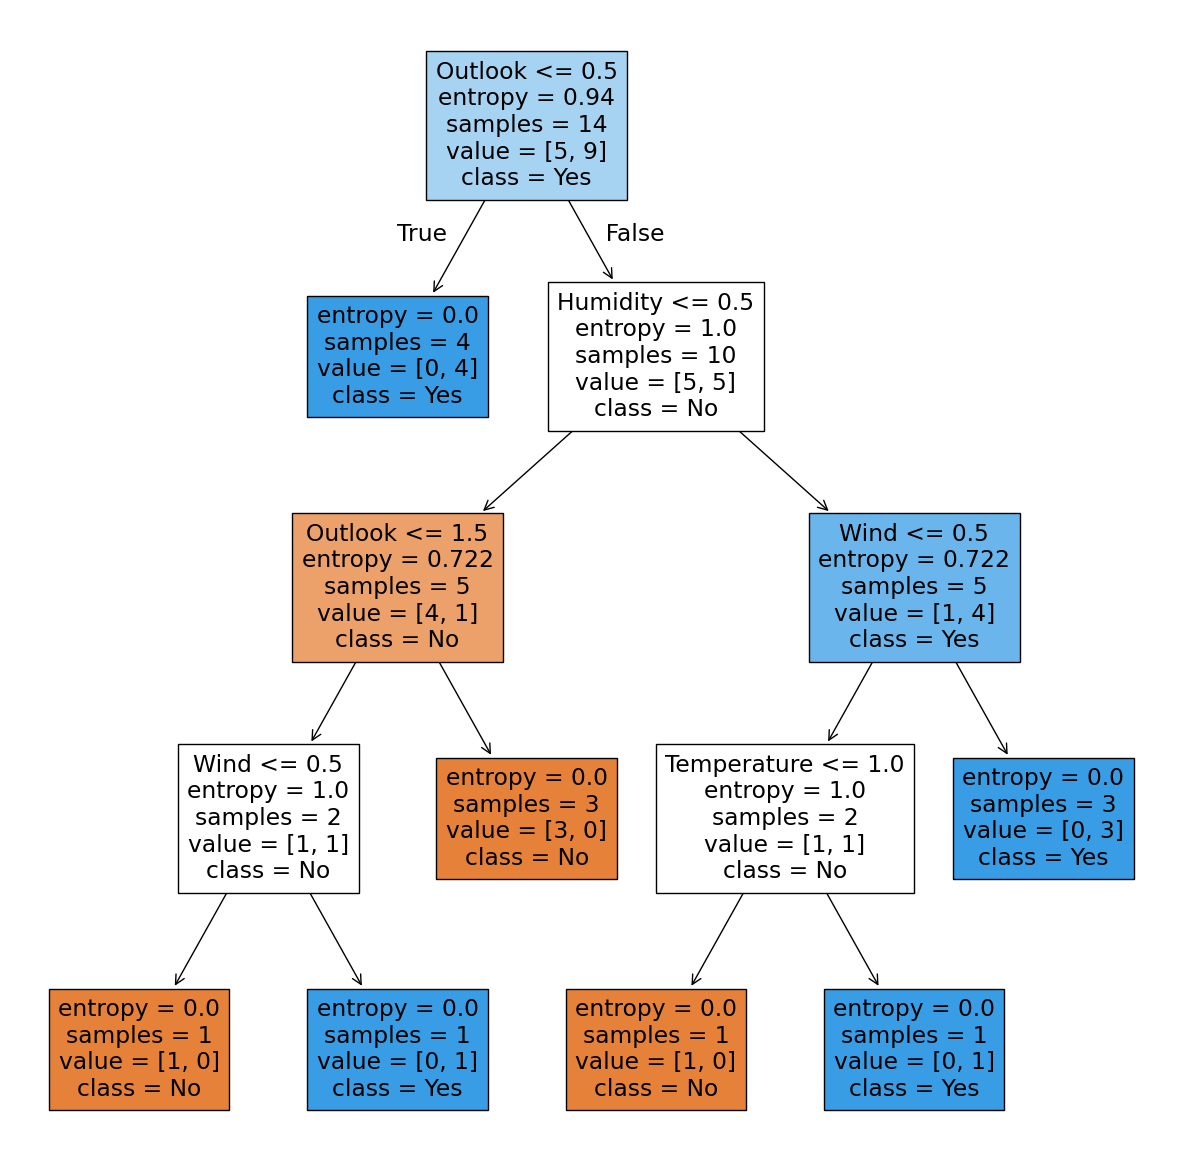

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 15))

plot_tree(
  model,
  feature_names=X.columns,
  class_names=["No", "Yes"],
  filled=True
)

plt.show()